# 01 · Sales and growth

How much did Cottonil really grow, and what does the sales mix look like?

Fiscal year = October to September (FY26 = Oct 2025 to Sep 2026). We use FY19 to FY26, the 8 complete years.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

lines = load_lines()
orders = load_orders()

years = list(range(2019, 2027))
lines = lines[lines["FY"].isin(years)]
orders = orders[orders["FY"].isin(years)]
print(f"{len(orders):,} orders and {len(lines):,} order lines")

535,359 orders and 1,128,591 order lines


## 1. Price vs volume

Prices rose a lot in Egypt after 2022. To separate price from volume, every line is re-valued at the
average FY19 price of its SKU. If sales at FY19 prices grow, that's real growth.

In [2]:
fy19_price = (lines[lines["FY"] == 2019].groupby("sku_id")["net_line_EGP"].sum()
              / lines[lines["FY"] == 2019].groupby("sku_id")["quantity"].sum())
lines["sales_at_fy19_prices"] = lines["quantity"] * lines["sku_id"].map(fy19_price)

yearly = lines.groupby("FY").agg(
    net_sales=("net_line_EGP", "sum"),
    sales_at_fy19_prices=("sales_at_fy19_prices", "sum"),
    units=("quantity", "sum"),
    margin=("margin_EGP", "sum"),
    discounts=("discount_line_EGP", "sum"),
)
yearly["price_index"] = yearly["net_sales"] / yearly["sales_at_fy19_prices"]
yearly["gross_margin_%"] = yearly["margin"] / yearly["net_sales"] * 100
yearly.round(2)

,net_sales,sales_at_fy19_prices,units,margin,discounts,price_index,gross_margin_%
FY,,,,,,,
2019,1.915504e+07,19155036.50,253025,7.347269e+06,865699.87,1.00,38.36
2020,2.457485e+07,21901412.11,289688,9.411066e+06,1118031.72,1.12,38.30
2021,3.098412e+07,24731889.39,325375,1.188031e+07,1381503.16,1.25,38.34
2022,4.633243e+07,28549812.85,375763,1.767849e+07,2106025.54,1.62,38.16
2023,7.416368e+07,32765636.80,436420,2.840547e+07,3388966.37,2.26,38.30
2024,1.309588e+08,38079324.93,500525,5.035005e+07,5890677.52,3.44,38.45
2025,2.113014e+08,43211515.73,567644,8.099003e+07,9511462.25,4.89,38.33
2026,2.892091e+08,47199810.55,620701,1.108935e+08,13023456.59,6.13,38.34


In [3]:
g = yearly.loc[2026] / yearly.loc[2019]
print(f"Net sales grew {g['net_sales']:.1f}x, prices {yearly.loc[2026, 'price_index']:.1f}x, units {g['units']:.1f}x")
print(f"Real growth per year (FY19-FY26): {(g['sales_at_fy19_prices'] ** (1 / 7) - 1):.1%}")
print(f"FY26 vs FY25: nominal {yearly.loc[2026, 'net_sales'] / yearly.loc[2025, 'net_sales'] - 1:+.1%}, "
      f"real {yearly.loc[2026, 'sales_at_fy19_prices'] / yearly.loc[2025, 'sales_at_fy19_prices'] - 1:+.1%}")

Net sales grew 15.1x, prices 6.1x, units 2.5x
Real growth per year (FY19-FY26): 13.7%
FY26 vs FY25: nominal +36.9%, real +9.2%


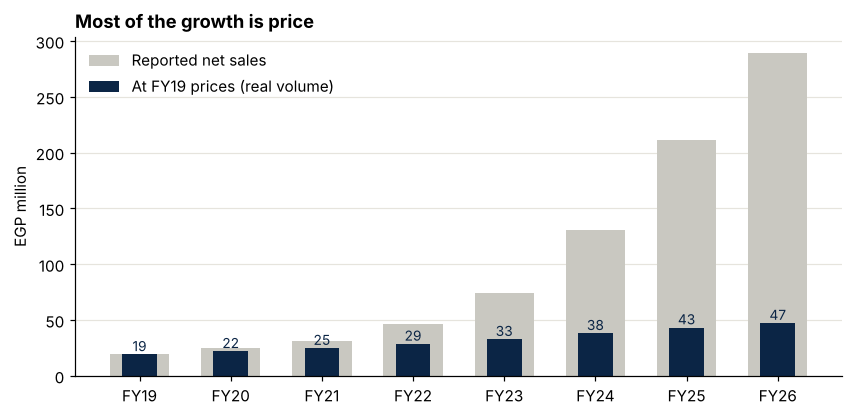

In [4]:
labels = [f"FY{str(y)[2:]}" for y in years]

plt.figure(figsize=(9, 4))
plt.bar(labels, yearly["net_sales"] / 1e6, color=GREY, width=0.65, label="Reported net sales")
plt.bar(labels, yearly["sales_at_fy19_prices"] / 1e6, color=NAVY, width=0.38, label="At FY19 prices (real volume)")
for i, v in enumerate(yearly["sales_at_fy19_prices"] / 1e6):
    plt.text(i, v + 3, f"{v:.0f}", ha="center", fontsize=9, color=NAVY)
plt.ylabel("EGP million")
plt.title("Most of the growth is price")
plt.legend()
save("01_real_growth")
plt.show()

Real growth is about **14% a year**, and +9% in FY26. Nominal growth (+37% in FY26) mostly reflects inflation.

## 2. Channels

In [5]:
channels = orders.groupby("sales_channel").agg(orders=("sales_order_id", "count"), net_sales=("net_before_tax_EGP", "sum"))
channels["share_%"] = channels["net_sales"] / channels["net_sales"].sum() * 100
channels["avg_order"] = channels["net_sales"] / channels["orders"]
channels.round(1)

,orders,net_sales,share_%,avg_order
sales_channel,,,,
E-commerce,96852,103707477.8,12.5,1070.8
Retail POS,384796,408808022.0,49.5,1062.4
Wholesale / reseller,53711,314163863.6,38.0,5849.2


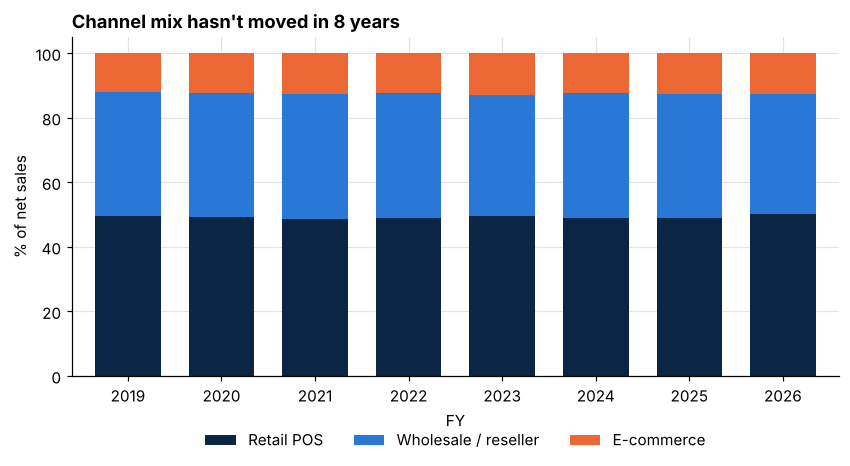

In [6]:
share = orders.pivot_table(index="FY", columns="sales_channel", values="net_before_tax_EGP", aggfunc="sum")
share = share.div(share.sum(axis=1), axis=0) * 100

share[["Retail POS", "Wholesale / reseller", "E-commerce"]].plot.bar(stacked=True, color=[NAVY, BLUE, ORANGE], figsize=(9, 4), rot=0, width=0.7)
plt.ylabel("% of net sales")
plt.title("Channel mix hasn't moved in 8 years")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3)
save("01_channels")
plt.show()

E-commerce is stuck at 12-13% of sales. Wholesale orders are ~5x bigger than store or online orders.

## 3. Categories

In [7]:
cat = lines.groupby("category_en").agg(net_sales=("net_line_EGP", "sum"), units=("quantity", "sum"), margin=("margin_EGP", "sum"))
cat["share_%"] = cat["net_sales"] / cat["net_sales"].sum() * 100
cat["margin_%"] = cat["margin"] / cat["net_sales"] * 100
cat = cat.sort_values("net_sales", ascending=False)
print(f"Top 3 categories = {cat['share_%'].head(3).sum():.0f}% of sales")
cat.round(1)

Top 3 categories = 56% of sales


,net_sales,units,margin,share_%,margin_%
category_en,,,,,
Men boxers,190520025.2,378310,72748293.2,23.0,38.2
Men tops,161811844.8,439094,62154069.1,19.6,38.4
Socks,114160306.0,903058,43824902.5,13.8,38.4
Men underwear,52166261.7,187547,20072959.3,6.3,38.5
Women pajamas,49401302.8,77461,18949093.6,6.0,38.4
Women tops,47748889.4,337141,18332351.7,5.8,38.4
Girls pajamas,38261727.8,157516,14701373.2,4.6,38.4
Boys pajamas,37569455.0,155684,14421051.4,4.5,38.4
Home textiles,33050672.1,97940,12602744.8,4.0,38.1


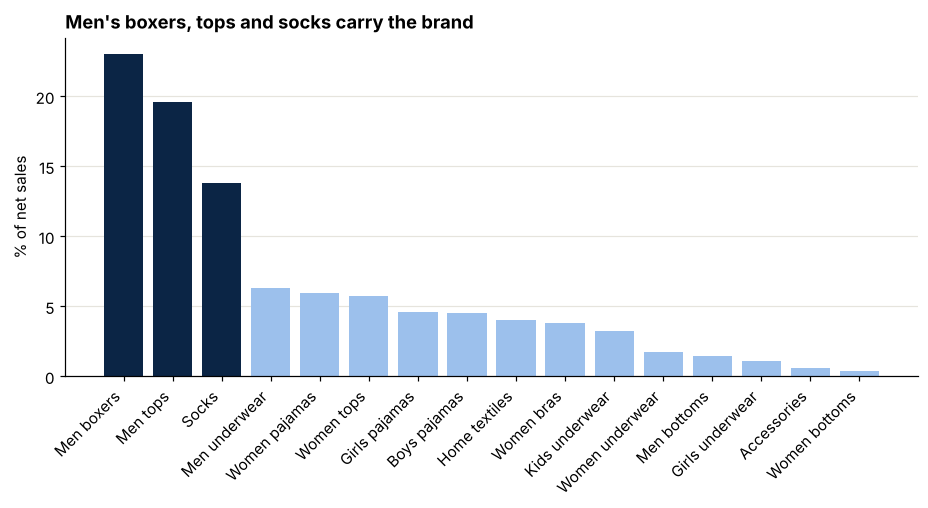

In [8]:
plt.figure(figsize=(10, 4))
plt.bar(cat.index, cat["share_%"], color=[NAVY] * 3 + [SKY] * (len(cat) - 3))
plt.xticks(rotation=45, ha="right")
plt.ylabel("% of net sales")
plt.title("Men's boxers, tops and socks carry the brand")
save("01_categories")
plt.show()

Margin is 38.0-38.6% in **every** category, so it can't be used to rank products here.

## 4. Seasonality

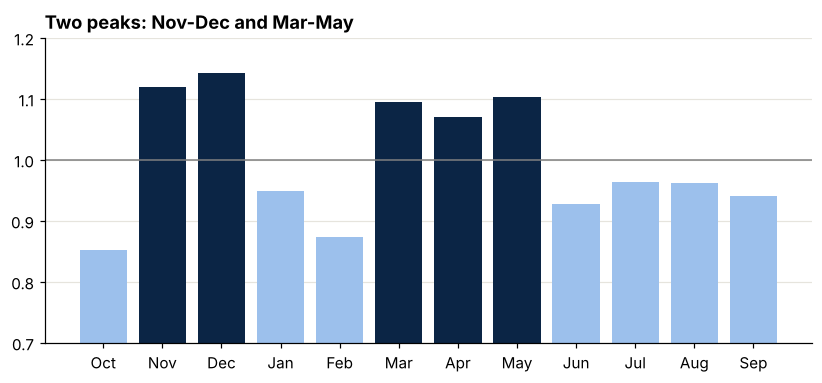

In [9]:
lines["month"] = lines["order_date"].dt.month
units = lines.groupby(["FY", "month"])["quantity"].sum().unstack()
index = units.div(units.mean(axis=1), axis=0)  # 1.0 = an average month in that year

month_order = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
names = ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"]
avg = index.loc[2020:, month_order].mean()   # FY19 October is only 12 days

plt.figure(figsize=(9, 3.6))
plt.bar(names, avg, color=[NAVY if v > 1.05 else SKY for v in avg])
plt.axhline(1, color="gray", lw=1)
plt.ylim(0.7, 1.2)
plt.title("Two peaks: Nov-Dec and Mar-May")
save("01_seasonality")
plt.show()

## 5. Discounts

In [10]:
lines["discount_level"] = (lines["discount_line_EGP"] / lines["gross_line_EGP"]).round(2)
disc = lines.groupby("discount_level").agg(lines=("sales_line_id", "count"), units_per_line=("quantity", "mean"),
                                           net=("net_line_EGP", "sum"), margin=("margin_EGP", "sum"))
disc["margin_%"] = disc["margin"] / disc["net"] * 100
disc["share_of_lines_%"] = disc["lines"] / disc["lines"].sum() * 100
print("Correlation discount vs quantity:", round(lines["discount_level"].corr(lines["quantity"]), 4))
disc[["share_of_lines_%", "units_per_line", "margin_%"]].round(2)

Correlation discount vs quantity: 0.0004


,share_of_lines_%,units_per_line,margin_%
discount_level,,,
0.00,46.02,2.98,41.02
0.03,12.00,2.98,39.18
0.05,17.01,3.00,37.87
0.10,14.97,2.98,34.36
0.15,8.00,2.99,30.62
0.20,1.99,2.98,26.47


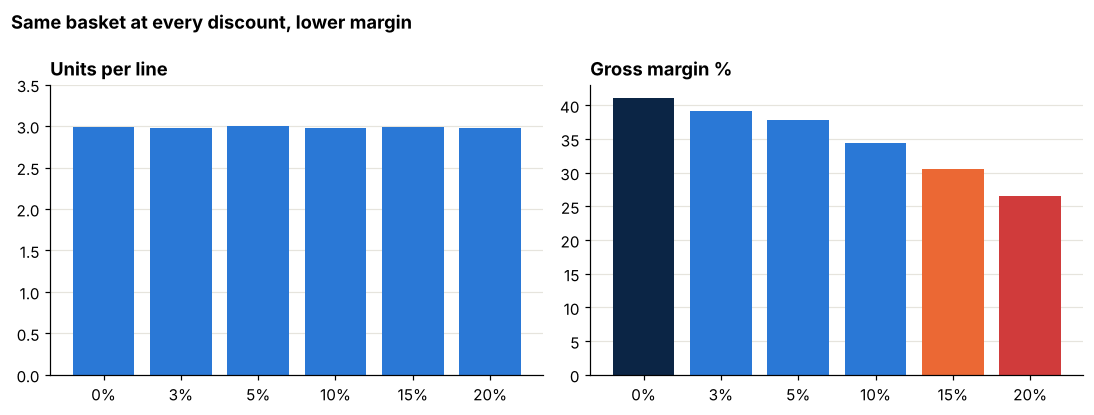

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.bar([f"{d:.0%}" for d in disc.index], disc["units_per_line"], color=BLUE)
a1.set_ylim(0, 3.5)
a1.set_title("Units per line")
a2.bar([f"{d:.0%}" for d in disc.index], disc["margin_%"], color=[NAVY, BLUE, BLUE, BLUE, ORANGE, RED])
a2.set_title("Gross margin %")
fig.suptitle("Same basket at every discount, lower margin", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save("01_discounts")
plt.show()

What if routine discounts were capped at 5%? (FY26 lines, no change in volume, since none was found)

In [12]:
fy26 = lines[lines["FY"] == 2026]
capped = fy26["gross_line_EGP"] * np.minimum(fy26["discount_level"], 0.05)
print("Extra gross profit in FY26:", millions((fy26["discount_line_EGP"] - capped).sum()))

Extra gross profit in FY26: 5.6M


## 6. Returns

In [13]:
returns = read("sales_returns.csv", dates=["return_date"])
returns["FY"] = fiscal_year(returns["return_date"])
r = returns[returns["FY"].isin(years)].groupby("FY")["refund_amount_EGP"].sum().to_frame("refunds")
r["%_of_sales"] = r["refunds"] / yearly["net_sales"] * 100
print(r.round(2))
print(returns["reason"].value_counts(normalize=True).round(3))

         refunds  %_of_sales
FY                          
2019   305786.82        1.60
2020   440519.13        1.79
2021   500195.49        1.61
2022   803082.05        1.73
2023  1197743.93        1.62
2024  2078816.13        1.59
2025  3277586.21        1.55
2026  4944141.35        1.71
reason
Other           0.203
Size issue      0.202
Defect claim    0.200
Exchange        0.198
Wrong item      0.198
Name: proportion, dtype: float64


Returns are low (1.6-1.8% of sales) and the 5 reasons are 20% each, which is too even to act on.

**Summary:** real growth ~14%/yr; channel and category mix stable; discounts cost margin with no effect on quantity.